In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
purchases = pd.read_csv("../data/cleaned_customer_data.csv")
purchases.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancellation,revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


In [41]:
purchases["invoice_date"] = pd.to_datetime(purchases["invoice_date"])
purchases["invoice_date"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 407664 entries, 0 to 407663
Series name: invoice_date
Non-Null Count   Dtype         
--------------   -----         
407664 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 3.1 MB


Calculates the RFM

In [42]:
# One day after the last recorded transaction
snapshot_date = (purchases["invoice_date"].max() + pd.Timedelta(days=1))

In [43]:
rfm = purchases.groupby("customer_id").agg({
    "invoice_date" : lambda x: (snapshot_date - x.max()).days, 
    "invoice" : "nunique",
    "revenue" : "sum"
})
# rfm

In [44]:
rfm.rename(columns={
    "invoice_date" : "recency",
    "invoice" : "frequency",
    "revenue" : "monetary"
}, inplace=True)

In [45]:
rfm.head()

,recency,frequency,monetary
customer_id,,,
12346.0,165,11,372.86
12347.0,3,2,1323.32
12348.0,74,1,222.16
12349.0,43,3,2671.14
12351.0,11,1,300.93


Assign RFM scores

In [46]:
# lower is better
rfm["R_score"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)

# higher is better
rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

# higher is better
rfm["M_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

In [47]:
rfm.head()

,recency,frequency,monetary,R_score,F_score,M_score
customer_id,,,,,,
12346.0,165,11,372.86,2,5,2
12347.0,3,2,1323.32,5,2,4
12348.0,74,1,222.16,2,1,1
12349.0,43,3,2671.14,3,3,5
12351.0,11,1,300.93,5,1,2


customer segments

In [48]:
rfm["RFM_score"] = (rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str))

In [49]:
rfm.head()

,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
customer_id,,,,,,,
12346.0,165,11,372.86,2,5,2,252
12347.0,3,2,1323.32,5,2,4,524
12348.0,74,1,222.16,2,1,1,211
12349.0,43,3,2671.14,3,3,5,335
12351.0,11,1,300.93,5,1,2,512


In [101]:
def customer_segment(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Champions"
    elif row["R_score"] >=3 and row["F_score"] >= 4:
        return "Loyal Customers"
    elif row["R_score"] >= 4 and row["F_score"] <= 2:
        return "New Customers"
    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"
    elif row["R_score"] <= 2:
        return "Lost Customers"
    else:
        return "Potential Loyalists"

rfm["segment"] = rfm.apply(customer_segment, axis=1)

In [51]:
rfm.head()

,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segment
customer_id,,,,,,,,
12346.0,165,11,372.86,2,5,2,252,At Risk
12347.0,3,2,1323.32,5,2,4,524,New Customers
12348.0,74,1,222.16,2,1,1,211,Lost Customers
12349.0,43,3,2671.14,3,3,5,335,Potential Loyalistts
12351.0,11,1,300.93,5,1,2,512,New Customers


Analyze customer segments

In [102]:
segment_analysis = rfm.groupby("segment").agg({
    "recency" : "mean",
    "frequency" : "mean",
    "monetary" : "mean"
}).round(2)

segment_analysis

,recency,frequency,monetary
segment,,,
At Risk,147.68,3.78,1523.25
Champions,13.70,10.52,5337.86
Lost Customers,212.49,1.13,405.44
Loyal Customers,51.97,6.12,2459.90
New Customers,19.51,1.30,495.19
Potential Loyalists,40.71,1.94,737.66


In [53]:
rfm["segment"].value_counts()

segment
Champions               1084
Lost Customers          1025
Potential Loyalistts     828
At Risk                  700
New Customers            360
Loyal Customers          315
Name: count, dtype: int64

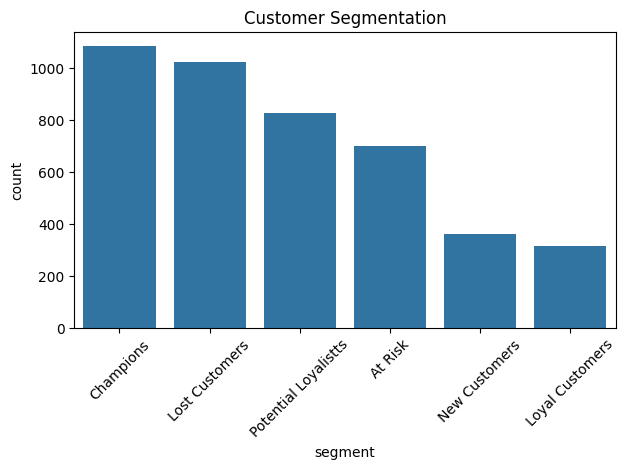

In [54]:
sns.countplot(
    data=rfm,
    x="segment",
    order=rfm["segment"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Customer Segmentation")
plt.tight_layout()
plt.savefig("customer_segments.png", dpi=300, bbox_inches="tight")
plt.show()

Which segment contains the most customers?
- The Champions segment with 1084

Which segment generates the most revenue?
- The Champions with average of 5337.86

How many customers are at risk?
- 700 Customers at risks

Which customers should receive loyalty offers?
- Customers with segment of loyal customers so they can become a champions and potential loyalists customers because they precet a huge presentage 

Which customers need re-engagement campaigns?
- Customers with a segment of at risk, lost customers and new customers

In [55]:
rfm.to_csv("../data/rfm_segments.csv")

Calculate orders per customer

In [56]:
customer_order = (purchases.groupby("customer_id")["invoice"].nunique())

Identify one-time and repeat customers

In [57]:
one_time = (customer_order == 1).sum()
repeat = (customer_order > 1).sum()
total = len(customer_order)

print("One time customer: ",one_time)
print("Repeated customer: ", repeat)
print("Total customer order: ", total)

One time customer:  1419
Repeated customer:  2893
Total customer order:  4312


In [58]:
repeat_rate = repeat / total * 100
print("Repeat Purchase Rate", round(repeat_rate,2), "%")

Repeat Purchase Rate 67.09 %


In [59]:
orders = (purchases.groupby(["customer_id", "invoice"]).agg(order_date = ("invoice_date", "min"), order_value = ("revenue","sum")).reset_index())

orders = orders.sort_values(["customer_id", "order_date"])

orders

,customer_id,invoice,order_date,order_value
0,12346.0,491725,2009-12-14 08:34:00,45.00
1,12346.0,491742,2009-12-14 11:00:00,22.50
2,12346.0,491744,2009-12-14 11:02:00,22.50
3,12346.0,492718,2009-12-18 10:47:00,22.50
4,12346.0,492722,2009-12-18 10:55:00,1.00
...,...,...,...,...
19208,18286.0,519785,2010-08-20 11:57:00,833.48
19209,18287.0,508581,2010-05-17 11:55:00,1071.61
19210,18287.0,523289,2010-09-21 12:17:00,862.00
19211,18287.0,523290,2010-09-21 12:19:00,30.60


Calculate the difference between purchases

In [82]:
orders["days_between_orders"] = (orders.groupby("customer_id")["order_date"].diff().dt.total_seconds()/86400) 

average_days = orders["days_between_orders"].mean()
median_days = orders["days_between_orders"].median()
print(round(average_days, 2))
print(round(median_days, 2))

38.87
20.9


In [81]:
orders

,customer_id,invoice,order_date,order_value,days_between_orders
0,12346.0,491725,2009-12-14 08:34:00,45.00,NaN
1,12346.0,491742,2009-12-14 11:00:00,22.50,0.101389
2,12346.0,491744,2009-12-14 11:02:00,22.50,0.001389
3,12346.0,492718,2009-12-18 10:47:00,22.50,3.989583
4,12346.0,492722,2009-12-18 10:55:00,1.00,0.005556
...,...,...,...,...,...
19208,18286.0,519785,2010-08-20 11:57:00,833.48,247.050000
19209,18287.0,508581,2010-05-17 11:55:00,1071.61,NaN
19210,18287.0,523289,2010-09-21 12:17:00,862.00,127.015278
19211,18287.0,523290,2010-09-21 12:19:00,30.60,0.001389


How long does it take customers to return?
- It takes customers an average of 38.44 days and to return which mean they takes around 20 days to return

Which customers purchase frequently?
- the repeated customers with 2893 high of them are the chapions and loyal customers

Are customers waiting longer between purchases?

- the avarage waiting time is 38.87 which can be influenced by unusually long gaps
- the middle waiting time is 20.9 which is less affected by outliers
- and these two numbers shows that the waiting time is longer but can be controlled because the avg still not exceeding the 50%.

In [84]:
repeat_orders = orders.dropna(subset=["days_between_orders"]).copy()
repeat_orders["purchase_month"] = (repeat_orders["order_date"].dt.to_period("M")) 

In [87]:
monthly_interval = (repeat_orders.groupby("purchase_month")["days_between_orders"].median())
monthly_interval

purchase_month
2009-12     4.006250
2010-01    20.772222
2010-02    15.906250
2010-03    19.910417
2010-04    24.154861
2010-05    22.986111
2010-06    23.221528
2010-07    22.075694
2010-08    28.174306
2010-09    27.585764
2010-10    26.172222
2010-11    20.072222
2010-12    13.497222
Freq: M, Name: days_between_orders, dtype: float64

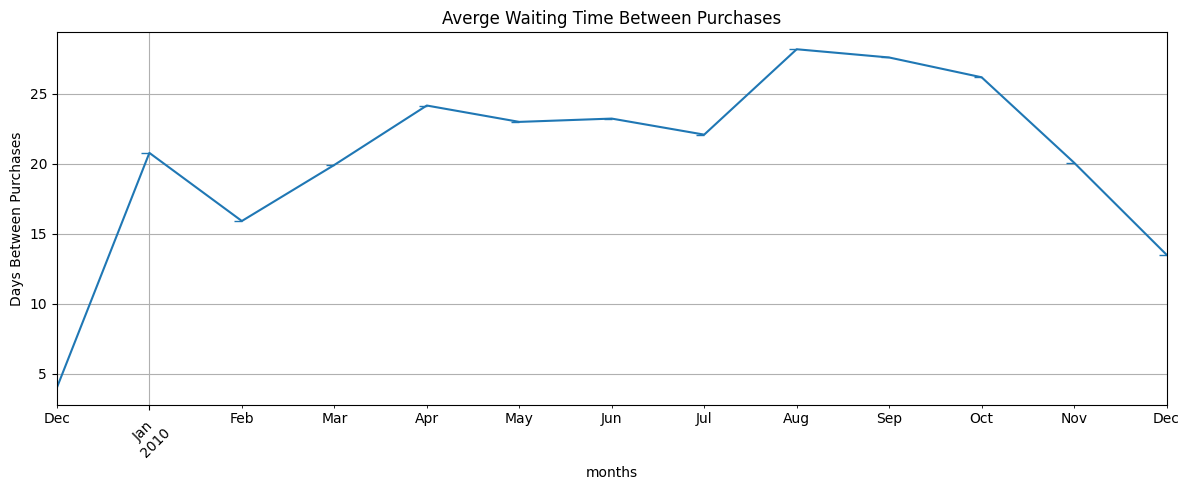

In [89]:
monthly_interval.plot(kind="line", figsize=(12,5), marker=0)
plt.title("Averge Waiting Time Between Purchases")
plt.xlabel("months")
plt.ylabel("Days Between Purchases")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.savefig("days_between_purchases.png", dpi=300, bbox_inches="tight")
plt.show()

In [92]:
orders = orders.merge(rfm[["segment"]], left_on="customer_id", right_index=True, how="left")

In [95]:
repeat_orders = orders.dropna(subset=["days_between_orders"]).copy()

In [97]:
segment_intervals = (repeat_orders.groupby("segment")["days_between_orders"].agg(["mean", "median","count"]).round(2))
segment_intervals

,mean,median,count
segment,,,
At Risk,49.73,33.04,1948
Champions,29.01,15.11,10325
Lost Customers,90.23,80.03,129
Loyal Customers,47.50,34.03,1614
New Customers,110.98,72.00,108
Potential Loyalistts,106.17,80.04,777


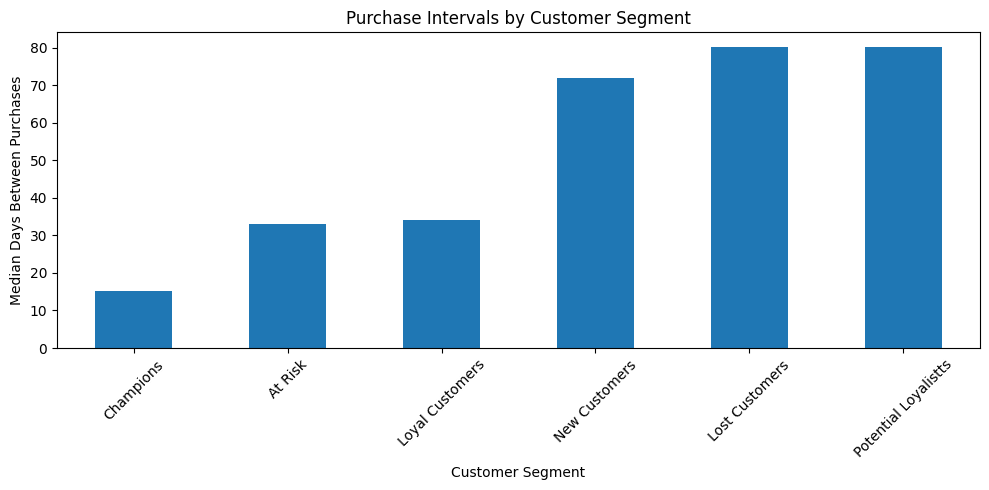

In [99]:
segment_intervals["median"].sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Purchase Intervals by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Median Days Between Purchases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("purchase_intervals_by_customer_segment.png", dpi=300, bbox_inches="tight")
plt.show()

Which segments have the shortest purchase intervals?
- Champions have the shortest purchase intervals with almost 15 days 

Customer retention analysis (Cohort Analysis)

In [63]:
purchases["invoice_month"] = (purchases["invoice_date"].dt.to_period("M"))

In [64]:
first_purchase = purchases.groupby("customer_id")["invoice_month"].min()
first_purchase.name = "cohort_month"

In [65]:
purchases = purchases.join(first_purchase, on="customer_id")

In [66]:
purchases

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancellation,revenue,invoice_month,cohort_month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.40,2009-12,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.00,2009-12,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.00,2009-12,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.80,2009-12,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.00,2009-12,2009-12
...,...,...,...,...,...,...,...,...,...,...,...,...
407659,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,False,5.90,2010-12,2009-12
407660,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,3.75,2010-12,2009-12
407661,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,3.75,2010-12,2009-12
407662,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,7.50,2010-12,2009-12


In [67]:
purchases["cohort_index"] = ((purchases["invoice_month"].dt.year - purchases["cohort_month"].dt.year) * 12
                             + (purchases["invoice_month"].dt.month - purchases["cohort_month"].dt.month) + 1)
purchases

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancellation,revenue,invoice_month,cohort_month,cohort_index
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.40,2009-12,2009-12,1
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.00,2009-12,2009-12,1
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.00,2009-12,2009-12,1
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.80,2009-12,2009-12,1
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.00,2009-12,2009-12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
407659,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,False,5.90,2010-12,2009-12,13
407660,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,3.75,2010-12,2009-12,13
407661,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,3.75,2010-12,2009-12,13
407662,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,7.50,2010-12,2009-12,13


In [68]:
cohort_data = (purchases.groupby(["cohort_month","cohort_index"])["customer_id"].nunique().reset_index())
cohort_data

,cohort_month,cohort_index,customer_id
0,2009-12,1,955
1,2009-12,2,337
2,2009-12,3,319
3,2009-12,4,406
4,2009-12,5,363
...,...,...,...
86,2010-10,2,97
87,2010-10,3,35
88,2010-11,1,325
89,2010-11,2,35


In [69]:
cohort_table = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customer_id",
)
cohort_table

cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13
cohort_month,,,,,,,,,,,,,
2009-12,955.0,337.0,319.0,406.0,363.0,343.0,360.0,327.0,321.0,346.0,403.0,473.0,237.0
2010-01,383.0,79.0,119.0,117.0,101.0,115.0,99.0,88.0,107.0,122.0,116.0,38.0,NaN
2010-02,374.0,89.0,84.0,109.0,92.0,75.0,72.0,107.0,95.0,103.0,27.0,NaN,NaN
2010-03,443.0,84.0,102.0,107.0,103.0,90.0,109.0,134.0,122.0,35.0,NaN,NaN,NaN
2010-04,294.0,57.0,57.0,48.0,54.0,66.0,81.0,77.0,20.0,NaN,NaN,NaN,NaN
2010-05,254.0,40.0,43.0,44.0,45.0,65.0,54.0,20.0,NaN,NaN,NaN,NaN,NaN
2010-06,270.0,47.0,51.0,55.0,62.0,77.0,18.0,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,186.0,29.0,34.0,55.0,54.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,162.0,33.0,48.0,52.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [70]:
cohort_size = cohort_table.iloc[:,0]
# cohort_size
retention = (cohort_table.divide(cohort_size, axis=0)) * 100
retention

cohort_index,1,2,3,4,5,6,7,8,9,10,11,12,13
cohort_month,,,,,,,,,,,,,
2009-12,100.0,35.287958,33.403141,42.513089,38.010471,35.916230,37.696335,34.240838,33.612565,36.230366,42.198953,49.528796,24.816754
2010-01,100.0,20.626632,31.070496,30.548303,26.370757,30.026110,25.848564,22.976501,27.937337,31.853786,30.287206,9.921671,NaN
2010-02,100.0,23.796791,22.459893,29.144385,24.598930,20.053476,19.251337,28.609626,25.401070,27.540107,7.219251,NaN,NaN
2010-03,100.0,18.961625,23.024831,24.153499,23.250564,20.316027,24.604966,30.248307,27.539503,7.900677,NaN,NaN,NaN
2010-04,100.0,19.387755,19.387755,16.326531,18.367347,22.448980,27.551020,26.190476,6.802721,NaN,NaN,NaN,NaN
2010-05,100.0,15.748031,16.929134,17.322835,17.716535,25.590551,21.259843,7.874016,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.407407,18.888889,20.370370,22.962963,28.518519,6.666667,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.591398,18.279570,29.569892,29.032258,10.215054,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.370370,29.629630,32.098765,11.728395,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


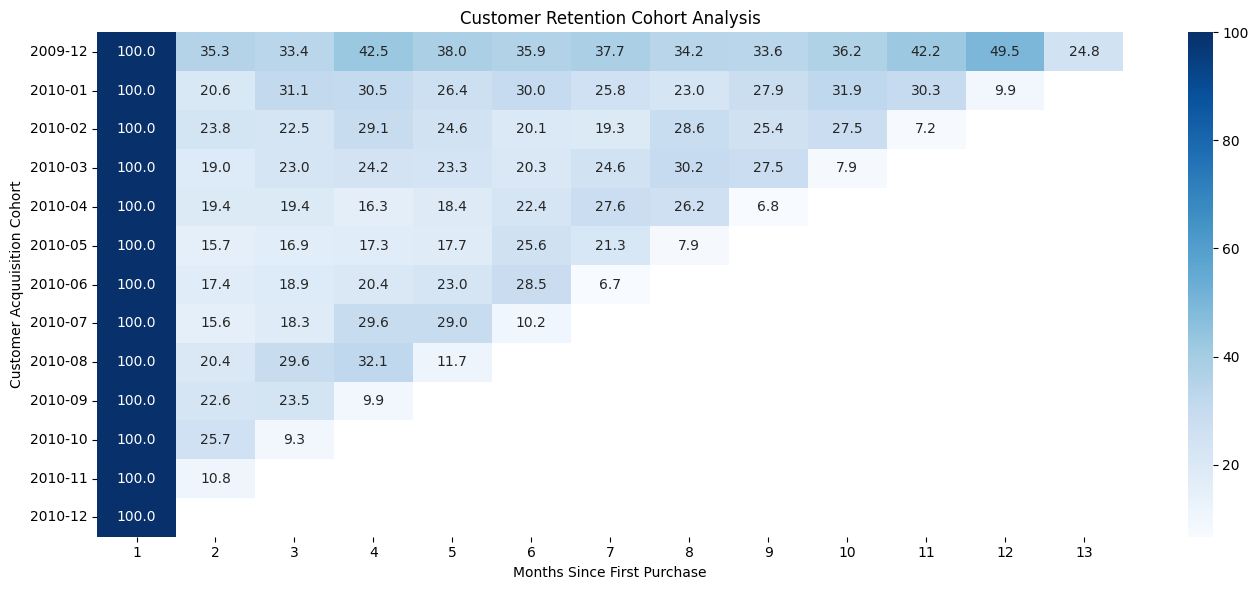

In [71]:
plt.figure(figsize=(14,6))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Customer Retention Cohort Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquuisition Cohort")
plt.tight_layout()
plt.savefig("retention_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [72]:
retention.to_csv("../data/customer_retention.csv")

In [73]:
customer_summary = rfm.reset_index()
customer_summary.to_csv("../data/customer_summary.csv", index=False)